# Vision Transformer (ViT)

In [1]:
#Mount Google Drive

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#Import required libraries

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision import datasets, transforms, models

from torch.utils.data import DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

import os

In [3]:
#Check GPU availability

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

Device: cuda
GPU: Tesla T4


## 1.Dataset Setup

In [4]:
#Define dataset paths

base_path = "/content/drive/MyDrive/PCOS_Project/SPLIT_DATASET"

train_path = os.path.join(base_path, "train")
test_path = os.path.join(base_path, "test")

print("Train path:", train_path)
print("Test path:", test_path)

print("\nTraining classes:", os.listdir(train_path))
print("Testing classes:", os.listdir(test_path))

Train path: /content/drive/MyDrive/PCOS_Project/SPLIT_DATASET/train
Test path: /content/drive/MyDrive/PCOS_Project/SPLIT_DATASET/test

Training classes: ['infected', 'noninfected']
Testing classes: ['infected', 'noninfected']


## 2.Preprocessing and Augmentation

In [5]:
#Define preprocessing and augmentation

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5, fill=0),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Preprocessing and augmentation defined successfully.")

Preprocessing and augmentation defined successfully.


## 3.Create Dataset and DataLoaders

In [6]:
#Create datasets and dataloaders

train_dataset = datasets.ImageFolder(
    root=train_path,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    root=test_path,
    transform=test_transform
)

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Dataset and DataLoaders created successfully.")
print("Class mapping:", train_dataset.class_to_idx)
print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Dataset and DataLoaders created successfully.
Class mapping: {'infected': 0, 'noninfected': 1}
Training samples: 3142
Testing samples: 786
Training batches: 99
Testing batches: 25


In [7]:
#Verify a batch of preprocessed training images

images, labels = next(iter(train_loader))

print("Batch verification")
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in this batch:", labels[:10].tolist())
print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

Batch verification
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in this batch: [0, 1, 0, 0, 1, 0, 0, 0, 1, 0]
Minimum pixel value: -2.1179039478302
Maximum pixel value: 2.640000104904175


## 4.Load Vision Transformer

In [8]:
#Load the pretrained Vision Transformer

vit_model = models.vit_b_16(
    weights=models.ViT_B_16_Weights.DEFAULT
)

print("Pretrained Vision Transformer loaded successfully.")
print(vit_model.heads)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 158MB/s]


Pretrained Vision Transformer loaded successfully.
Sequential(
  (head): Linear(in_features=768, out_features=1000, bias=True)
)


In [9]:
#Modify the classification head for two classes

num_features = vit_model.heads.head.in_features

vit_model.heads.head = nn.Linear(
    num_features,
    2
)

vit_model = vit_model.to(device)

print("Vision Transformer classification head updated successfully.")
print(vit_model.heads)
print("Model device:", device)

Vision Transformer classification head updated successfully.
Sequential(
  (head): Linear(in_features=768, out_features=2, bias=True)
)
Model device: cuda


## 5.Loss Function and Optimizer

In [10]:
#Define the loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    vit_model.parameters(),
    lr=0.0001
)

print("Loss function and optimizer defined successfully.")
print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function and optimizer defined successfully.
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


## 6.Train Vision Transformer

In [11]:
#Train the Vision Transformer

num_epochs = 5

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):

    vit_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        #Clear previous gradients
        optimizer.zero_grad()

        #Forward pass
        outputs = vit_model(images)

        #Calculate loss
        loss = criterion(outputs, labels)

        #Backward pass
        loss.backward()

        #Update model parameters
        optimizer.step()

        #Accumulate loss
        running_loss += loss.item() * images.size(0)

        #Calculate predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_dataset)
    epoch_accuracy = correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy * 100:.2f}%"
    )

Epoch [1/5] Loss: 0.1722 Accuracy: 93.16%
Epoch [2/5] Loss: 0.0647 Accuracy: 97.99%
Epoch [3/5] Loss: 0.0416 Accuracy: 98.95%
Epoch [4/5] Loss: 0.0329 Accuracy: 99.11%
Epoch [5/5] Loss: 0.0438 Accuracy: 98.66%


In [12]:
#Save the trained Vision Transformer model

model_save_path = "/content/drive/MyDrive/PCOS_Project/vision_transformer.pth"

torch.save(vit_model.state_dict(), model_save_path)

print("Vision Transformer model saved successfully.")
print("Saved model path:", model_save_path)

Vision Transformer model saved successfully.
Saved model path: /content/drive/MyDrive/PCOS_Project/vision_transformer.pth


## 7.Evaluate Vision Transformer

In [13]:
#Evaluate the Vision Transformer on the test dataset

vit_model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = vit_model(images)

        probabilities = torch.softmax(outputs, dim=1)
        _, predictions = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities[:, 1].cpu().numpy())

print("Vision Transformer evaluation completed successfully.")
print("Number of test labels:", len(all_labels))
print("Number of predictions:", len(all_predictions))
print("Number of probabilities:", len(all_probabilities))

Vision Transformer evaluation completed successfully.
Number of test labels: 786
Number of predictions: 786
Number of probabilities: 786


## 8.Calculate Metrics

In [14]:
#Calculate evaluation metrics

accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    all_labels,
    all_probabilities
)

print("Vision Transformer Evaluation Metrics")
print("-------------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Vision Transformer Evaluation Metrics
-------------------------------------
Accuracy:  0.9860
Precision: 0.9618
Recall:    0.9679
F1-score:  0.9649
ROC-AUC:   0.9972


## 9.Classification Report

In [15]:
#Generate the classification report

report = classification_report(
    all_labels,
    all_predictions,
    target_names=["infected", "noninfected"],
    zero_division=0
)

print("Vision Transformer Classification Report")
print("----------------------------------------")
print(report)

Vision Transformer Classification Report
----------------------------------------
              precision    recall  f1-score   support

    infected       0.99      0.99      0.99       630
 noninfected       0.96      0.97      0.96       156

    accuracy                           0.99       786
   macro avg       0.98      0.98      0.98       786
weighted avg       0.99      0.99      0.99       786



## 10.Confusion Matrix

Vision Transformer Confusion Matrix
-----------------------------------
[[624   6]
 [  5 151]]


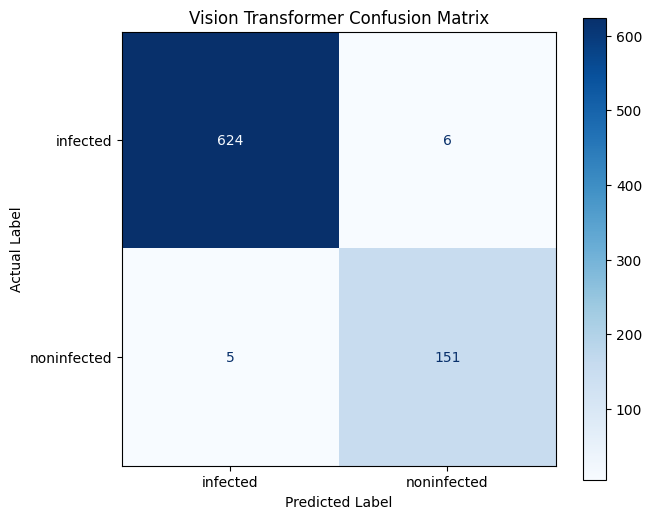

Confusion matrix saved successfully.
Saved path: /content/drive/MyDrive/PCOS_Project/vision_transformer_results/vit_confusion_matrix.png


In [18]:
#Generate and save the confusion matrix

results_dir = "/content/drive/MyDrive/PCOS_Project/vision_transformer_results"

os.makedirs(results_dir, exist_ok=True)

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Vision Transformer Confusion Matrix")
print("-----------------------------------")
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["infected", "noninfected"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Vision Transformer Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

confusion_matrix_path = os.path.join(
    results_dir,
    "vit_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Confusion matrix saved successfully.")
print("Saved path:", confusion_matrix_path)

## 11.ROC Curve

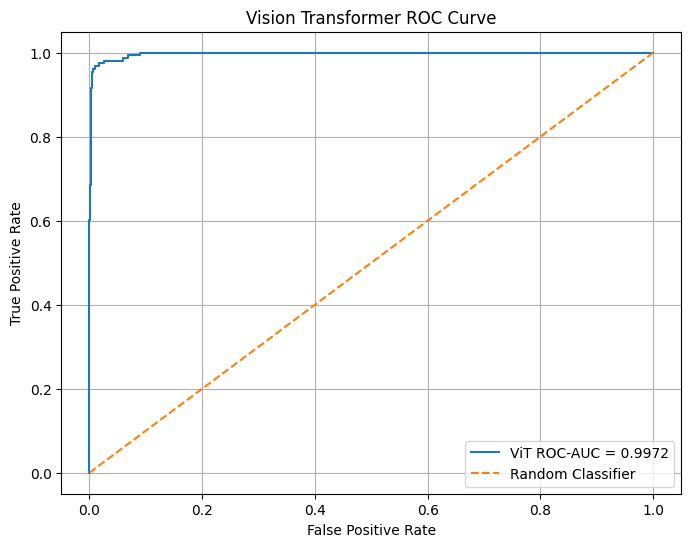

ROC-AUC: 0.9972
ROC curve saved successfully.
Saved path: /content/drive/MyDrive/PCOS_Project/vision_transformer_results/vit_roc_curve.png


In [19]:
#Generate and save the ROC curve

results_dir = "/content/drive/MyDrive/PCOS_Project/vision_transformer_results"

os.makedirs(results_dir, exist_ok=True)

fpr, tpr, thresholds = roc_curve(
    all_labels,
    all_probabilities
)

roc_auc_value = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr,
    tpr,
    label=f"ViT ROC-AUC = {roc_auc_value:.4f}"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Vision Transformer ROC Curve")
ax.legend(loc="lower right")
ax.grid(True)

roc_curve_path = os.path.join(
    results_dir,
    "vit_roc_curve.png"
)

plt.savefig(
    roc_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"ROC-AUC: {roc_auc_value:.4f}")
print("ROC curve saved successfully.")
print("Saved path:", roc_curve_path)

## 12.Save Vision Transformer Training Graphs

In [21]:
# Save Vision Transformer results to CSV

import pandas as pd
import os

results_dir = "/content/drive/MyDrive/PCOS_Project/vision_transformer_results"
os.makedirs(results_dir, exist_ok=True)

results_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

csv_path = os.path.join(
    results_dir,
    "vit_results.csv"
)

results_df.to_csv(csv_path, index=False)

print("Vision Transformer results saved successfully.")
print("Saved path:", csv_path)

Vision Transformer results saved successfully.
Saved path: /content/drive/MyDrive/PCOS_Project/vision_transformer_results/vit_results.csv


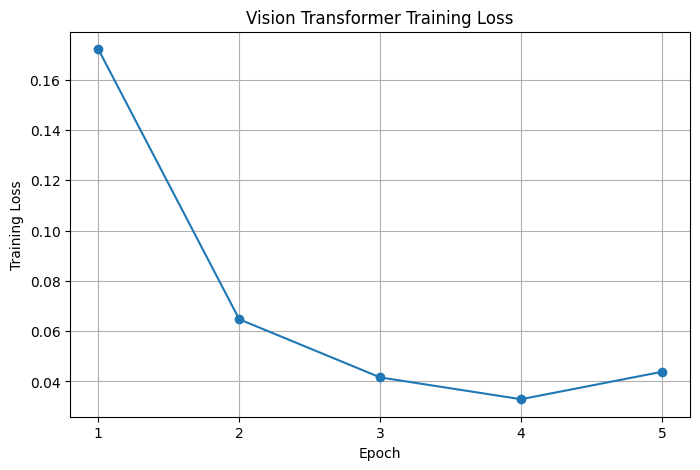

Training loss graph saved successfully.
Saved path: /content/drive/MyDrive/PCOS_Project/vision_transformer_results/vit_training_loss.png


In [22]:
# Plot and save Vision Transformer training loss

import matplotlib.pyplot as plt
import os

results_dir = "/content/drive/MyDrive/PCOS_Project/vision_transformer_results"
os.makedirs(results_dir, exist_ok=True)

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Vision Transformer Training Loss")
plt.xticks(list(epochs_range))
plt.grid(True)

loss_plot_path = os.path.join(
    results_dir,
    "vit_training_loss.png"
)

plt.savefig(
    loss_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Training loss graph saved successfully.")
print("Saved path:", loss_plot_path)

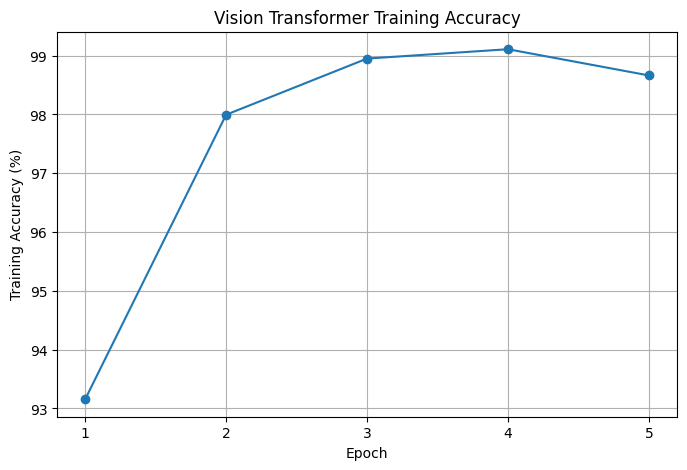

Training accuracy graph saved successfully.
Saved path: /content/drive/MyDrive/PCOS_Project/vision_transformer_results/vit_training_accuracy.png


In [23]:
# Plot and save Vision Transformer training accuracy

import matplotlib.pyplot as plt
import os

results_dir = "/content/drive/MyDrive/PCOS_Project/vision_transformer_results"
os.makedirs(results_dir, exist_ok=True)

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    [accuracy * 100 for accuracy in train_accuracies],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("Vision Transformer Training Accuracy")
plt.xticks(list(epochs_range))
plt.grid(True)

accuracy_plot_path = os.path.join(
    results_dir,
    "vit_training_accuracy.png"
)

plt.savefig(
    accuracy_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Training accuracy graph saved successfully.")
print("Saved path:", accuracy_plot_path)